# UCS420 Assignment 7 - Harnoor Kaur Dran



In [3]:
ROLL_NO = 1024170436         # <-- your full roll number
NAME = "Harnoor Kaur Dran"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170436   Name: Harnoor Kaur Dran   Fingerprint: 9B94DAE4   Tickets: 13

Ticket_ID                                                                             Ticket_Text
      T01       MATLAB failed to open after resetting my password. The same problem occurs again.
      T02 I keep getting logged out of the wifi after resetting my password. It worked yesterday.
      T03                                                    Email me at helpdesk@university.edu.
      T04           I keep getting logged out of the student portal on my laptop. This is urgent.
      T05                                                             The file is 95.5% uploaded.
      T06                          I couldn't connect to the LMS since yesterday. This is urgent.
      T07                                         The student portal failed to open. Please help.
      T08                                                   Nothing works and nobody has replied.
      T09                    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
# Q1: Apply the official preprocessing pipeline to every generated ticket.
processed = [process_ticket(text) for text in df["Ticket_Text"]]

q1_rows = []
for ticket_id, text, result in zip(df["Ticket_ID"], df["Ticket_Text"], processed):
    q1_rows.append({
        "Ticket_ID": ticket_id,
        "Number of sentences": len(result["sentences"]),
        "Number of tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"]),
    })
q1_table = pd.DataFrame(q1_rows)
count_cols = ["Number of sentences", "Number of tokens", "Punctuation tokens", "Stopwords", "Final tokens"]
total = {"Ticket_ID": "TOTAL", **{c: int(q1_table[c].sum()) for c in count_cols}, "Unique tokens": "not additive"}
display(pd.concat([q1_table, pd.DataFrame([total])], ignore_index=True))

# Show the actual lists for one focus ticket (use the first focus ID if available).
selected_id = FOCUS[0] if FOCUS else df.iloc[0]["Ticket_ID"]
selected_idx = df.index[df["Ticket_ID"] == selected_id][0]
selected = processed[selected_idx]
print(f"Selected ticket: {selected_id}\n{df.loc[selected_idx, 'Ticket_Text']}\n")
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])

# Observation: contractions are split by the standard tokenizer; pieces such as n't, 's,
# and ca can remain after stopword/punctuation filtering because they are not themselves
# English stopwords and are not punctuation-only tokens.
contraction_fragments = {"n't", "'s", "'re", "'ve", "'ll", "'d", "'m", "ca", "wo"}
found_fragments = [token for token in selected["final"] if token in contraction_fragments]
print("\nQ1 observation — contraction fragments in the selected ticket:", found_fragments if found_fragments else "None in this selected ticket")
print("These fragments can occur because word_tokenize() splits contractions into parts; the pipeline removes stopwords and punctuation-only tokens, but some fragments remain.")


,Ticket_ID,Number of sentences,Number of tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,15,2,6,14,7
1,T02,2,17,2,7,16,8
2,T03,1,7,2,2,7,3
3,T04,2,17,2,8,16,7
4,T05,1,7,2,2,7,3
5,T06,2,14,2,5,13,7
6,T07,2,10,2,2,9,6
7,T08,1,7,1,2,7,4
8,T09,2,9,2,3,8,4
9,T10,2,14,2,5,12,7


Selected ticket: T01
MATLAB failed to open after resetting my password. The same problem occurs again.

Actual tokens: ['matlab', 'failed', 'to', 'open', 'after', 'resetting', 'my', 'password', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['to', 'after', 'my', 'the', 'same', 'again']
Final tokens: ['matlab', 'failed', 'open', 'resetting', 'password', 'problem', 'occurs']

Q1 observation — contraction fragments in the selected ticket: None in this selected ticket
These fragments can occur because word_tokenize() splits contractions into parts; the pipeline removes stopwords and punctuation-only tokens, but some fragments remain.


---
## Q2. Regular expressions



In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

LONG_WORD_RE = r"\b[A-Za-z]{6,}\b"
# Match version/decimal values first, then comma-grouped integers and ordinary integers.
NUMBER_RE = r"(?<![\w.])(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)+(?![\w.])|(?<![\w.])\d{1,3}(?:,\d{3})+(?!\d)|(?<![\w.])\d+(?![\w.]|,\d{3})"
CAPITALIZED_RE = r"\b[A-Z][a-zA-Z]*\b"
VOWEL_START_RE = r"\b[AEIOUaeiou][A-Za-z]*\b"
EMAIL_RE = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
URL_RE = r"\b(?:https?://|www\.)[^\s<>\"']+"
PHONE_RE = r"(?<!\w)(?:\+\d{1,3}[\s.-]?)?(?:\(?\d{3,5}\)?[\s.-]?)?\d{3,5}[\s.-]\d{3,5}(?!\w)"

def replace_url(match):
    value = match.group(0)
    trailing = ""
    while value and value[-1] in ".,!?;:)":
        trailing = value[-1] + trailing
        value = value[:-1]
    return "<URL>" + trailing

def regex_analysis(text):
    return {
        "Words >5 letters": re.findall(LONG_WORD_RE, text),
        "Numbers / decimals / versions": re.findall(NUMBER_RE, text),
        "Capitalized words": re.findall(CAPITALIZED_RE, text),
        "Vowel-start words": re.findall(VOWEL_START_RE, text),
        "Replaced text": re.sub(PHONE_RE, "<PHONE>", re.sub(URL_RE, replace_url, re.sub(EMAIL_RE, "<EMAIL>", text))),
    }

for _, row in df.iterrows():
    print(f"\n{row['Ticket_ID']}: {row['Ticket_Text']}")
    for label, value in regex_analysis(row["Ticket_Text"]).items():
        print(f"{label}: {value}")

print("\n--- TEST_LINES regex checks ---")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST_LINE {i}: {line}")
    for label, value in regex_analysis(line).items():
        print(f"{label}: {value}")

# Sentence-initial capitalization estimate: capitalized matches that begin immediately
# after start-of-string or sentence-ending punctuation plus whitespace.
capitalized_matches = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    for m in re.finditer(CAPITALIZED_RE, text):
        prefix = text[:m.start()]
        if not prefix.strip() or re.search(r"[.!?]\s*$", prefix):
            capitalized_matches.append((ticket_id, m.group(), m.start()))
all_capitalized = [(ticket_id, m.group(), m.start())
                   for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"])
                   for m in re.finditer(CAPITALIZED_RE, text)]
print("\nTotal capitalized-word matches:", len(all_capitalized))
print("Capitalized matches at sentence starts:", len(capitalized_matches))
print("Examples of sentence-initial matches:", capitalized_matches[:12])
print(f"Q2 observation: {len(capitalized_matches)} of {len(all_capitalized)} capitalized-word matches occur at a ticket/sentence start. This is an estimate; capitalized names, acronyms and product names may also appear elsewhere.")

# Patterns are tested on both the generated ticket corpus and the supplied TEST_LINES.
# Note: phone-number formats vary; these patterns cover the formats in this assignment's tests.


T01: MATLAB failed to open after resetting my password. The same problem occurs again.
Words >5 letters: ['MATLAB', 'failed', 'resetting', 'password', 'problem', 'occurs']
Numbers / decimals / versions: []
Capitalized words: ['MATLAB', 'The']
Vowel-start words: ['open', 'after', 'occurs', 'again']
Replaced text: MATLAB failed to open after resetting my password. The same problem occurs again.

T02: I keep getting logged out of the wifi after resetting my password. It worked yesterday.
Words >5 letters: ['getting', 'logged', 'resetting', 'password', 'worked', 'yesterday']
Numbers / decimals / versions: []
Capitalized words: ['I', 'It']
Vowel-start words: ['I', 'out', 'of', 'after', 'It']
Replaced text: I keep getting logged out of the wifi after resetting my password. It worked yesterday.

T03: Email me at helpdesk@university.edu.
Words >5 letters: ['helpdesk', 'university']
Numbers / decimals / versions: []
Capitalized words: ['Email']
Vowel-start words: ['Email', 'at', 'university', 

---
## Q3. Custom tokenizer


In [9]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One RegexpTokenizer pattern. Specific/long formats must precede generic words and numbers.
TOKEN_PATTERN = (
    r"https?://[^\s<>\"']*[^\s<>\"'.,!?;:)]|www\.[^\s<>\"']*[^\s<>\"'.,!?;:)]|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"(?:\+\d{1,3}[\s.-]?)?(?:\d{5}[\s.-]?\d{5}|\d{3,5}[\s.-]\d{3,5}[\s.-]\d{3,5})|"
    r"\d+(?:\.\d+){2,}|\d+\.\d+|"
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"
    r"\d{1,3}(?:,\d{3})+|\d+|[A-Za-z]+|[^\w\s]"
)
_custom_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _custom_tokenizer.tokenize(str(text))

print("--- TEST_LINES: custom vs word_tokenize ---")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST_LINE {i}\nword_tokenize: {word_tokenize(line)}\nmy_tokenize:   {my_tokenize(line)}")

custom_ticket_tokens = [my_tokenize(text) for text in df["Ticket_Text"]]
standard_ticket_tokens = [word_tokenize(text) for text in df["Ticket_Text"]]
different_ticket_rows = []
for ticket_id, text, standard, custom in zip(df["Ticket_ID"], df["Ticket_Text"], standard_ticket_tokens, custom_ticket_tokens):
    if standard != custom:
        different_ticket_rows.append({"Ticket_ID": ticket_id, "Ticket_Text": text,
                                      "word_tokenize()": standard, "my_tokenize()": custom})
print(f"\nTickets tokenized differently: {len(different_ticket_rows)} / {len(df)}")
for row in different_ticket_rows:
    print(f"\n{row['Ticket_ID']}: {row['Ticket_Text']}\nword_tokenize: {row['word_tokenize()']}\nmy_tokenize:   {row['my_tokenize()']}")

print("\nUse the exact token lists above as evidence. The custom pattern is designed to preserve contractions, hyphenated words, decimals/versions, emails, URLs and phone numbers where they occur.")
print(f"Q3 observation: {len(different_ticket_rows)} of {len(df)} generated tickets have different token lists under the two tokenizers.")
if different_ticket_rows:
    example = different_ticket_rows[0]
    print(f"First exact example ({example['Ticket_ID']}): {example['Ticket_Text']}")
    print("Standard tokens:", example["word_tokenize()"])
    print("Custom tokens:  ", example["my_tokenize()"])


--- TEST_LINES: custom vs word_tokenize ---

TEST_LINE 1
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
my_tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST_LINE 2
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
my_tokenize:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST_LINE 3
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']
my_tokenize:   ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', 

---
## Q4. Stemming and lemmatization


In [10]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()
unique_final = sorted({token for result in processed for token in result["final"]})

# Choose a suffix only after checking the actual unique final tokens. Prefer -ing if
# at least two dataset words use it; otherwise choose the first supported common suffix.
suffix_options = [("ing", r"ing$"), ("ed", r"ed$"), ("ly", r"ly$"), ("s", r"s$"), ("er", r"er$")]
suffix_evidence = {}
for suffix, pattern in suffix_options:
    suffix_evidence[suffix] = [w for w in unique_final if len(w) > len(suffix) + 2 and w.endswith(suffix)]
chosen = next(((s, p) for s, p in suffix_options if len(suffix_evidence[s]) >= 2), None)
if chosen is None:
    chosen = ("s", r"s$")
regexp_suffix, regexp_pattern = chosen
regexp_stemmer = RegexpStemmer(regexp_pattern)
print("RegexpStemmer suffix pattern:", regexp_pattern)
print("Dataset evidence:", suffix_evidence[regexp_suffix][:10])
if len(suffix_evidence[regexp_suffix]) >= 2:
    print(f"Justification: at least two dataset words end in '-{regexp_suffix}', so this rule tests a suffix actually present in this corpus.")
else:
    print("Justification: no tested suffix occurred on at least two unique final tokens; '-s' is used as a fallback and this limitation should be noted.")

# POS tags are attached to the unique final-token vocabulary.
tagged_words = pos_tag(unique_final)
pos_by_word = dict(tagged_words)
def to_wordnet_pos(tag):
    if tag.startswith("J"): return "a"
    if tag.startswith("V"): return "v"
    if tag.startswith("N"): return "n"
    if tag.startswith("R"): return "r"
    return "n"

stem_rows = []
for word in unique_final:
    tag = pos_by_word.get(word, "NN")
    row = {
        "Word": word,
        "POS tag": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "WordNet lemma (POS-aware)": lemmatizer.lemmatize(word, pos=to_wordnet_pos(tag)),
    }
    if len({row[k] for k in ["Porter", "Lancaster", "Regexp", "WordNet lemma (POS-aware)"]}) > 1:
        stem_rows.append(row)
stem_table = pd.DataFrame(stem_rows, columns=["Word", "POS tag", "Porter", "Lancaster", "Regexp", "WordNet lemma (POS-aware)"])
print("Words for which at least two methods differ:", len(stem_table))
display(stem_table)

# Print concrete examples for the observation question.
changed = [(w, porter.stem(w)) for w in unique_final if porter.stem(w) != w]
print("\nPotential over-stemming example (inspect whether the stem remains a meaningful word):", changed[:5])
print("Under-stemming note: suffix-only rules can leave related forms unchanged when they use a different suffix; inspect the displayed table for such a pair.")

RegexpStemmer suffix pattern: ing$
Dataset evidence: ['asking', 'getting', 'nothing', 'resetting', 'responding', 'uploading', 'working']
Justification: at least two dataset words end in '-ing', so this rule tests a suffix actually present in this corpus.
Words for which at least two methods differ: 29


,Word,POS tag,Porter,Lancaster,Regexp,WordNet lemma (POS-aware)
0,failed,VBN,fail,fail,failed,fail
1,file,NN,file,fil,file,file
2,getting,VBG,get,get,gett,get
3,keeps,NNS,keep,keep,keeps,keep
4,lms,NNS,lm,lms,lms,lm
5,logged,VBD,log,log,logged,log
6,mobile,VBP,mobil,mobl,mobile,mobile
7,nobody,NN,nobodi,nobody,nobody,nobody
8,nothing,NN,noth,noth,noth,nothing
9,occurs,VBZ,occur,occ,occurs,occur



Potential over-stemming example (inspect whether the stem remains a meaningful word): [('asking', 'ask'), ('failed', 'fail'), ('getting', 'get'), ('keeps', 'keep'), ('lms', 'lm')]
Under-stemming note: suffix-only rules can leave related forms unchanged when they use a different suffix; inspect the displayed table for such a pair.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: all tokens,155,77,0.4968
1,S2: tokens without punctuation,130,73,0.5615
2,S3: final tokens,76,51,0.6711
3,S4: S3 after Porter stemming,76,47,0.6184


Top 10 words — S1


,Word,Frequency
0,.,22
1,the,12
2,i,5
3,is,4
4,to,3
5,my,3
6,keep,3
7,getting,3
8,logged,3
9,out,3


Top 10 words — S3


,Word,Frequency
0,keep,3
1,getting,3
2,logged,3
3,yesterday,3
4,lms,3
5,please,3
6,failed,2
7,open,2
8,resetting,2
9,password,2


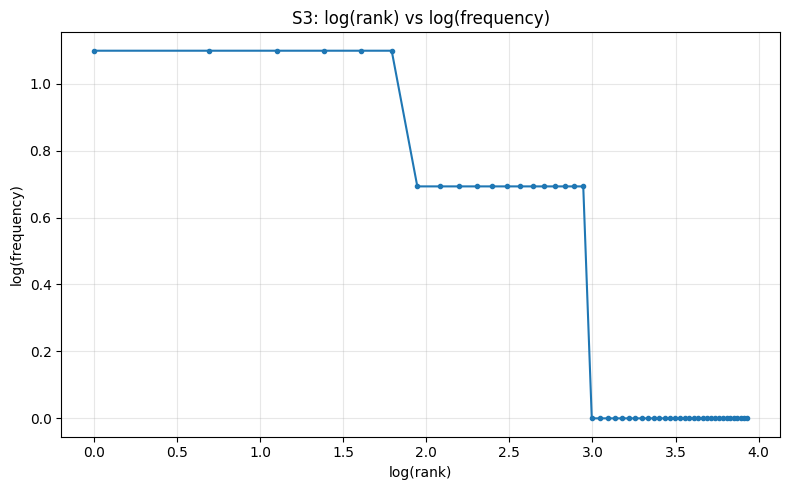

Top 5 bigrams — S1


,Bigram,Frequency
0,. the,6
1,. i,4
2,i keep,3
3,keep getting,3
4,getting logged,3


Top 5 bigrams — S3


,Bigram,Frequency
0,keep getting,3
1,getting logged,3
2,failed open,2
3,resetting password,2
4,problem occurs,2



Interpretation (a): S1 TTR = 0.4968; S4 TTR = 0.6184.
TTR increases in this corpus because stemming changed the unique-token count and its ratio to the total; refer to the displayed counts for the exact reason.


In [11]:
from collections import Counter
import math
import matplotlib.pyplot as plt

# S1 = every token from process_ticket, including punctuation; S2 = without punctuation;
# S3 = official final tokens; S4 = Porter-stemmed S3.
S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for result in processed for token in result["tokens"] if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def stats(name, corpus):
    total = len(corpus)
    unique = len(set(corpus))
    return {"Corpus": name, "Total tokens": total, "Unique tokens": unique,
            "TTR": unique / total if total else 0.0}

stats_table = pd.DataFrame([
    stats("S1: all tokens", S1),
    stats("S2: tokens without punctuation", S2),
    stats("S3: final tokens", S3),
    stats("S4: S3 after Porter stemming", S4),
])
display(stats_table.style.format({"TTR": "{:.4f}"}))

def top_words(corpus, n=10):
    return pd.DataFrame(Counter(corpus).most_common(n), columns=["Word", "Frequency"])
print("Top 10 words — S1")
display(top_words(S1, 10))
print("Top 10 words — S3")
display(top_words(S3, 10))

# Zipf-style rank-frequency plot, using natural logarithms.
frequency_values = sorted(Counter(S3).values(), reverse=True)
if frequency_values:
    ranks = list(range(1, len(frequency_values) + 1))
    plt.figure(figsize=(8, 5))
    plt.plot([math.log(r) for r in ranks], [math.log(f) for f in frequency_values], marker="o", markersize=3)
    plt.xlabel("log(rank)")
    plt.ylabel("log(frequency)")
    plt.title("S3: log(rank) vs log(frequency)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("S3 is empty; no rank-frequency plot can be drawn.")

def top_bigrams(corpus, n=5):
    return pd.DataFrame([(f"{a} {b}", count) for (a, b), count in Counter(zip(corpus[:-1], corpus[1:])).most_common(n)],
                        columns=["Bigram", "Frequency"])
print("Top 5 bigrams — S1")
display(top_bigrams(S1, 5))
print("Top 5 bigrams — S3")
display(top_bigrams(S3, 5))

s1_ttr = len(set(S1)) / len(S1) if S1 else 0
s4_ttr = len(set(S4)) / len(S4) if S4 else 0
print(f"\nInterpretation (a): S1 TTR = {s1_ttr:.4f}; S4 TTR = {s4_ttr:.4f}.")
if s4_ttr < s1_ttr:
    print("TTR decreases because Porter stemming maps some related word forms to the same stem, reducing the unique-type count relative to total tokens.")
elif s4_ttr > s1_ttr:
    print("TTR increases in this corpus because stemming changed the unique-token count and its ratio to the total; refer to the displayed counts for the exact reason.")
else:
    print("TTR is unchanged because the changes in unique types and total tokens leave the ratio the same.")

---
## Q6. Interpretation (a–d)

The cell below generates short, dataset-specific answers from the tickets produced for your roll number. Read the examples and keep the explanations tied to the printed outputs. If the generated vocabulary does not contain a defensible example, the cell says so instead of inventing one.

In [12]:
# Q6: Dataset-specific written interpretations (generated from the actual outputs above).
from itertools import combinations

print("Q6(a) — TTR from S1 to S4")
print(f"S1: {len(S1)} tokens, {len(set(S1))} unique tokens, TTR={s1_ttr:.4f}.")
print(f"S4: {len(S4)} tokens, {len(set(S4))} unique stems, TTR={s4_ttr:.4f}.")
if s4_ttr < s1_ttr:
    print("TTR decreased. Stemming merged some word forms into shared stems, so the proportion of unique types became smaller.")
elif s4_ttr > s1_ttr:
    print("TTR increased in this corpus. Compare the displayed unique counts and totals: TTR is unique types divided by total tokens, so its direction depends on their ratio.")
else:
    print("TTR stayed the same. The ratio of unique types to total tokens is equal for S1 and S4, even though the token forms may differ.")

print("\nQ6(b) — One exact tokenizer difference")
diff_example = None
for line in [str(x) for x in df["Ticket_Text"]] + TEST_LINES:
    standard = word_tokenize(line)
    custom = my_tokenize(line)
    if standard != custom:
        diff_example = (line, standard, custom)
        break
if diff_example:
    line, standard, custom = diff_example
    print("Text:", line)
    print("word_tokenize():", standard)
    print("my_tokenize():  ", custom)
    print("Explanation: compare these exact lists; the custom tokenizer keeps at least one format together that the standard tokenizer splits (or handles differently).")
else:
    print("No difference was found in the current generated tickets or TEST_LINES. Report this result honestly and inspect the two token lists above.")

print("\nQ6(c) — Example of a potentially undesirable stem")
# Prefer an actual stem that is substantially shorter than the original and differs from
# the POS-aware lemma. This is a candidate for discussion, not a claim that every stem is wrong.
undesirable = []
for word in unique_final:
    tag = pos_by_word.get(word, "NN")
    lemma = lemmatizer.lemmatize(word, pos=to_wordnet_pos(tag))
    stem = porter.stem(word)
    if stem != word and stem != lemma and len(stem) <= max(2, len(word)-3):
        undesirable.append((word, stem, lemma, tag))
if undesirable:
    word, stem, lemma, tag = sorted(undesirable, key=lambda x: (len(x[1]), x[0]))[0]
    print(f"Example: {word!r} (POS={tag}) -> Porter stem {stem!r}; WordNet lemma {lemma!r}.")
    print("Explanation: the Porter output is a mechanically shortened stem, not necessarily a standalone dictionary word; the lemma provides a more linguistically meaningful base form when the POS tag is suitable.")
else:
    changed_words = [(w, porter.stem(w)) for w in unique_final if porter.stem(w) != w]
    if changed_words:
        word, stem = changed_words[0]
        print(f"Candidate from this dataset: {word!r} -> {stem!r}. Check the Q4 table before calling it undesirable; no strong example met the automatic criteria.")
    else:
        print("No final token changed under Porter stemming, so this corpus does not provide a stemming example for this question.")

print("\nQ6(d) — POS-aware lemmatization example")
lemma_examples = []
for word in unique_final:
    tag = pos_by_word.get(word, "NN")
    lemma = lemmatizer.lemmatize(word, pos=to_wordnet_pos(tag))
    stem = porter.stem(word)
    if lemma != word and lemma != stem:
        lemma_examples.append((word, tag, stem, lemma))
if lemma_examples:
    word, tag, stem, lemma = sorted(lemma_examples, key=lambda x: (len(x[0]), x[0]))[0]
    print(f"Example: {word!r}, POS tag={tag}, Porter stem={stem!r}, POS-aware WordNet lemma={lemma!r}.")
    print("Explanation: lemmatization uses a vocabulary and the word's part of speech to return a dictionary form; stemming removes endings by rule and may return a fragment.")
else:
    print("No word in this generated vocabulary produced a POS-aware lemma different from both the original and Porter stem. Use a suitable differing row from the Q4 table if one is present; do not invent an example.")

print("\nQ4 observation support — stemming examples")
# Find actual vocabulary pairs whose Porter stems remain different despite a simple
# suffix relationship. This is only evidence of a possible under-stemming case.
word_set = set(unique_final)
pair_candidates = []
for w in unique_final:
    for suffix in ("ing", "ed", "s", "ly", "er"):
        if w.endswith(suffix) and len(w) > len(suffix) + 2:
            base = w[:-len(suffix)]
            for candidate_base in (base, base + "e", base + "y"):
                if candidate_base in word_set and porter.stem(candidate_base) != porter.stem(w):
                    pair_candidates.append((candidate_base, w, porter.stem(candidate_base), porter.stem(w)))
if pair_candidates:
    a, b, sa, sb = pair_candidates[0]
    print(f"Possible under-stemming pair: {a!r} -> {sa!r}, {b!r} -> {sb!r}. Verify they are related forms in context before using this example.")
else:
    print("No clear suffix-related pair in the generated vocabulary was left with different Porter stems; do not claim an under-stemming example unless the Q4 table provides one.")


Q6(a) — TTR from S1 to S4
S1: 155 tokens, 77 unique tokens, TTR=0.4968.
S4: 76 tokens, 47 unique stems, TTR=0.6184.
TTR increased in this corpus. Compare the displayed unique counts and totals: TTR is unique types divided by total tokens, so its direction depends on their ratio.

Q6(b) — One exact tokenizer difference
Text: Email me at helpdesk@university.edu.
word_tokenize(): ['Email', 'me', 'at', 'helpdesk', '@', 'university.edu', '.']
my_tokenize():   ['Email', 'me', 'at', 'helpdesk@university.edu', '.']
Explanation: compare these exact lists; the custom tokenizer keeps at least one format together that the standard tokenizer splits (or handles differently).

Q6(c) — Example of a potentially undesirable stem
Example: 'nothing' (POS=NN) -> Porter stem 'noth'; WordNet lemma 'nothing'.
Explanation: the Porter output is a mechanically shortened stem, not necessarily a standalone dictionary word; the lemma provides a more linguistically meaningful base form when the POS tag is suitable.
